# Module 8 — Task 2: ML pricing, compared with Black-Scholes

**The business question (brief, verbatim):**
> NovaFin has exposure to equity options. Management wants to know: **Can ML improve option pricing and help manage derivatives exposure?**

**Task 2 (brief, verbatim):**
> **Task 2 — ML pricing.** Predict: market price using ml models and compare performance w.r.t Black-Scholes

**In plain words:** train ML models to predict what the market pays for each option, and see on options they have never seen whether they get closer than the Black-Scholes formula. Then use the result to manage the book's risk with a hedge.

**What Task 1 told us before starting** (its step 8): the market price is BS ± about 3% random noise, with no pattern by any input; a learned correction made prices worse. So the honest expectation is that ML can match BS but not beat it. This task tests that properly.

**Terms** (Task 1's terms table covers option, call, put, strike, spot, BS, Greeks)

| Term | What it is, simply |
| --- | --- |
| **Direct ML** | The model learns the market price from the inputs alone, without the BS formula |
| **Hybrid** | BS price + a correction learned by ML |
| **Linear regression / random forest / LightGBM / neural network** | Four ways to learn a price: a weighted sum of inputs; many decision trees averaged; trees built one after another, each fixing the last one's errors; layers of simple units that can learn curved shapes |
| **5-fold check** | Split the training options into 5 parts; train on 4, test on the 5th, rotate. Picks the model without touching the test set |
| **Paired comparison** | BS and ML priced on the same unseen options; the ₹ difference in their gaps gets a 95% range by resampling |
| **Delta hedge** | Hold shares that cancel the book's stock exposure, so small stock moves don't change its value |

| Step | What it does |
| --- | --- |
| 0 | Setup and Task 1's outputs |
| 1 | Inputs, targets and the split (M8-02, M8-03, M8-10, M8-12) |
| 2 | Eight models compared on the training options (5-fold) (M8-11) |
| 3 | Overfitting check |
| 4 | Choosing the models: the factors in plain words |
| 5 | The test, used once: ML vs BS (M8-13) |
| 6 | Does it hold everywhere? By price, moneyness, call/put |
| 6b | By stock: pricing |
| 7 | Better than luck? The shuffled-correction test |
| 8 | What the models rely on |
| 9 | Managing exposure: four hedging choices, 21 stress scenarios (M8-14, M8-15) |
| 9c | How likely a loss is; running each hedge; the written-book check (M8-17, M8-20) |
| 9d | The choice rule and the recommended hedge by stock (M8-15) |
| 9e | What goes to Module 9: protecting the capital Module 9 puts into equities (M8-21) |
| 10 | What it means in ₹ |
| 11 | What the results say and the recommendation |
| 12 | Save the outputs |

## 0. Setup and Task 1's outputs

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")        # stops a harmless Windows warning
# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_08_derivatives"
T1_DIR = MODULE_DIR / "outputs" / "task1"
OUT_DIR = MODULE_DIR / "outputs" / "task2"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
import lightgbm as lgb

from m08_data import load_options
from m08_black_scholes import bs_price, greeks
from m08_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, GAIN, LOSS
apply_style()
plt.close("all")

SEED = 42                                   # project rule P-06: every random step uses 42
MIN_PRICE_FOR_PCT = 1.0                     # M8-06: % gaps only for options worth ₹1 or more
pd.set_option("display.width", 220, "display.max_columns", 30)
K1 = json.loads((T1_DIR / "key_numbers.json").read_text(encoding="utf-8"))
t1 = pd.read_csv(T1_DIR / "FINAL_M8_T1_bs_benchmark.csv")
print(f"From Task 1: BS average gap ₹{K1['mae']:.2f}, bias ₹{K1['bias']:+.2f}, {K1['below_floor']} impossible prices, "
      f"learned-correction R² {K1['task2_review']['gap_r2']:+.2f}")


def save_table(table: pd.DataFrame, name: str) -> None:
    """Save a table as CSV in outputs/task2."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    """Save a chart as PNG in outputs/task2 and show it."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
    plt.show()

From Task 1: BS average gap ₹5.84, bias ₹+0.05, 359 impossible prices, learned-correction R² -0.10


## 1. Inputs, targets and the split (decisions M8-02, M8-03, M8-10, M8-12)
- **Inputs (M8-10):** spot ÷ strike, ln(spot ÷ strike), time, volatility, rate, call/put, volatility × √time. No stock name (Task 1: it makes no difference). The hybrid also gets BS ÷ strike.
- **Targets, divided by the strike** so a ₹100 and a ₹3,000 stock's options are comparable:
  - direct: market price ÷ strike;
  - hybrid: (market − BS) ÷ strike, added back to BS.
  Predictions are multiplied back by the strike to get ₹.
- **Split (M8-03):** 80% training, 20% test, random, seed 42. The test is used once, in step 5.
- **Impossible prices (M8-12):** the 359 below-floor options are removed from training; the test is reported with and without them.

In [2]:
df = load_options()
df["Is call"] = (df.Option_Type == "Call").astype(int)
df = df.merge(t1[["Option ID", "BS price (₹, ours)", "Market price below floor?", "Moneyness band", "In the money by", "Delta"]],
              left_on="Option_ID", right_on="Option ID")
df["BS"] = df["BS price (₹, ours)"]; df["Below floor"] = df["Market price below floor?"] == "Yes"
df["S/K"] = df.Spot / df.Strike; df["ln(S/K)"] = np.log(df["S/K"]); df["Vol x sqrt(T)"] = df.Volatility * np.sqrt(df.Time_to_Maturity)
df["BS/K"] = df.BS / df.Strike
INPUTS = ["S/K", "ln(S/K)", "Time_to_Maturity", "Volatility", "Interest_Rate", "Is call", "Vol x sqrt(T)"]
SETUPS = {"Direct": INPUTS, "Hybrid": INPUTS + ["BS/K"]}

train_all, test = train_test_split(df, test_size=0.2, random_state=SEED)
train = train_all[~train_all["Below floor"]].copy()
print(f"Training options: {len(train_all):,} → {len(train):,} after removing {train_all['Below floor'].sum()} impossible prices; "
      f"test options: {len(test):,} (of which {test['Below floor'].sum()} impossible)")


def target(part: pd.DataFrame, setup: str) -> np.ndarray:
    """What the model learns, per ₹1 of strike: the price (direct) or the gap from BS (hybrid)."""
    return (part.Market_Price / part.Strike if setup == "Direct" else (part.Market_Price - part.BS) / part.Strike).to_numpy()


def to_price(part: pd.DataFrame, setup: str, pred: np.ndarray) -> np.ndarray:
    """Turn a prediction back into a ₹ price; never below 0."""
    p = pred * part.Strike.to_numpy() + (0 if setup == "Direct" else part.BS.to_numpy())
    return np.maximum(p, 0)

Training options: 8,000 → 7,709 after removing 291 impossible prices; test options: 2,000 (of which 68 impossible)


## 2. Eight models compared on the training options (decision M8-11)
Four model types × two set-ups, each judged by 5-fold checks on the training options only. BS is scored on the same folds. Measure: average gap from the market in ₹ (MAE), as in Task 1.

In [3]:
def make_model(name: str):
    """The four model types, settings fixed in advance, all seeded with 42."""
    if name == "Linear regression":
        return make_pipeline(StandardScaler(), LinearRegression())
    if name == "Random forest":
        return RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
    if name == "LightGBM":
        return lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=30, random_state=SEED, verbose=-1)
    return make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 64), alpha=1e-4, max_iter=600, early_stopping=True,
                                                        random_state=SEED))


MODEL_NAMES = ["Linear regression", "Random forest", "LightGBM", "Neural network"]
kf = KFold(5, shuffle=True, random_state=SEED)
rows = []
for setup, cols in SETUPS.items():
    for name in MODEL_NAMES:
        fold_mae, fold_train_mae = [], []
        for tr, va in kf.split(train):
            a, b = train.iloc[tr], train.iloc[va]
            m = make_model(name).fit(a[cols], target(a, setup))
            fold_mae.append(np.abs(to_price(b, setup, m.predict(b[cols])) - b.Market_Price).mean())
            fold_train_mae.append(np.abs(to_price(a, setup, m.predict(a[cols])) - a.Market_Price).mean())
        rows.append({"Set-up": setup, "Model": name, "MAE on held-out folds (₹)": np.mean(fold_mae), "Spread across folds (₹)": np.std(fold_mae),
                     "MAE on its own training folds (₹)": np.mean(fold_train_mae)})
bs_folds = [np.abs(train.iloc[va].BS - train.iloc[va].Market_Price).mean() for _, va in kf.split(train)]
rows.append({"Set-up": "Formula", "Model": "Black-Scholes", "MAE on held-out folds (₹)": np.mean(bs_folds),
             "Spread across folds (₹)": np.std(bs_folds), "MAE on its own training folds (₹)": np.mean(bs_folds)})
cv = pd.DataFrame(rows)
cv["vs BS (₹; + = worse than BS)"] = cv["MAE on held-out folds (₹)"] - np.mean(bs_folds)
display(cv.round(3))

,Set-up,Model,MAE on held-out folds (₹),Spread across folds (₹),MAE on its own training folds (₹),vs BS (₹; + = worse than BS)
0,Direct,Linear regression,112.022,3.514,111.836,106.486
1,Direct,Random forest,9.577,0.270,6.280,4.042
2,Direct,LightGBM,8.016,0.305,5.298,2.481
3,Direct,Neural network,10.281,0.432,8.312,4.746
4,Hybrid,Linear regression,5.591,0.145,5.587,0.056
5,Hybrid,Random forest,5.730,0.149,3.708,0.195
6,Hybrid,LightGBM,5.936,0.122,4.124,0.401
7,Hybrid,Neural network,10.973,0.915,8.474,5.438
8,Formula,Black-Scholes,5.535,0.146,5.535,0.000


## 3. Overfitting check
A model that fits its training options much better than unseen ones has learned noise. Gap = unseen MAE − training MAE (₹); near 0 is good.

In [4]:
cv["Overfitting gap (₹)"] = cv["MAE on held-out folds (₹)"] - cv["MAE on its own training folds (₹)"]
display(cv[["Set-up", "Model", "MAE on its own training folds (₹)", "MAE on held-out folds (₹)", "Overfitting gap (₹)"]].round(3))

,Set-up,Model,MAE on its own training folds (₹),MAE on held-out folds (₹),Overfitting gap (₹)
0,Direct,Linear regression,111.836,112.022,0.186
1,Direct,Random forest,6.280,9.577,3.298
2,Direct,LightGBM,5.298,8.016,2.718
3,Direct,Neural network,8.312,10.281,1.969
4,Hybrid,Linear regression,5.587,5.591,0.004
5,Hybrid,Random forest,3.708,5.730,2.023
6,Hybrid,LightGBM,4.124,5.936,1.812
7,Hybrid,Neural network,8.474,10.973,2.499
8,Formula,Black-Scholes,5.535,5.535,0.000


## 4. Choosing the models: the factors in plain words
The best model of each set-up (lowest held-out MAE) goes to the test. BS is the benchmark.

In [5]:
ml = cv[cv["Set-up"] != "Formula"]
BEST = {s: ml[ml["Set-up"] == s].sort_values("MAE on held-out folds (₹)").iloc[0]["Model"] for s in SETUPS}
EXPLAIN = {"Linear regression": "Easy: one weight per input", "Random forest": "Hard: hundreds of trees", "LightGBM": "Hard: hundreds of trees",
           "Neural network": "Hard: thousands of weights"}
factors = pd.DataFrame([{"Choice": f"{s}: {BEST[s]}", "Held-out MAE (₹)": f"{r['MAE on held-out folds (₹)']:.2f}",
                         "vs BS": f"{r['vs BS (₹; + = worse than BS)']:+.2f} ₹ ({'worse' if r['vs BS (₹; + = worse than BS)'] > 0 else 'better'})",
                         "Learned noise (overfitting gap)": f"₹{r['Overfitting gap (₹)']:.2f}", "Explainable?": EXPLAIN[BEST[s]],
                         "Needs BS?": "No" if s == "Direct" else "Yes: adds to BS"}
                        for s in SETUPS for r in [ml[(ml["Set-up"] == s) & (ml.Model == BEST[s])].iloc[0]]]
                       + [{"Choice": "Black-Scholes (benchmark)", "Held-out MAE (₹)": f"{np.mean(bs_folds):.2f}", "vs BS": "—",
                           "Learned noise (overfitting gap)": "None: nothing is learned", "Explainable?": "Yes: a formula every desk knows",
                           "Needs BS?": "—"}])
display(factors)
print("Going to the test:", BEST)

,Choice,Held-out MAE (₹),vs BS,Learned noise (overfitting gap),Explainable?,Needs BS?
0,Direct: LightGBM,8.02,+2.48 ₹ (worse),₹2.72,Hard: hundreds of trees,No
1,Hybrid: Linear regression,5.59,+0.06 ₹ (worse),₹0.00,Easy: one weight per input,Yes: adds to BS
2,Black-Scholes (benchmark),5.54,—,None: nothing is learned,Yes: a formula every desk knows,—


Going to the test: {'Direct': 'LightGBM', 'Hybrid': 'Linear regression'}


## 5. The test, used once: ML vs BS (decision M8-13)
The chosen models are refitted on all training options and priced on the 2,000 test options they have never seen. **Better than BS** means a lower average gap in ₹ and in %, with the 95% range of the ₹ difference (BS gap − ML gap, paired on the same options, 1,000 resamples) above 0.

In [6]:
fitted = {}
test = test.copy()
for s, cols in SETUPS.items():
    fitted[s] = make_model(BEST[s]).fit(train[cols], target(train, s))
    test[f"{s} ML price"] = to_price(test, s, fitted[s].predict(test[cols]))
PRICERS = {"Black-Scholes": "BS", f"Direct ML ({BEST['Direct']})": "Direct ML price", f"Hybrid ML ({BEST['Hybrid']})": "Hybrid ML price"}


def score(part: pd.DataFrame, col: str) -> dict:
    """MAE, RMSE, bias (₹) and median |gap %| (options ≥ ₹1) of one pricer against the market."""
    g = part.Market_Price - part[col]
    big = part.BS >= MIN_PRICE_FOR_PCT
    return {"MAE (₹)": g.abs().mean(), "RMSE (₹)": np.sqrt((g ** 2).mean()), "Bias (₹)": g.mean(),
            "Median |gap| (% of price)": (g[big].abs() / part.loc[big, col].clip(lower=0.01)).median()}


def paired(part: pd.DataFrame, col: str, n: int = 1000) -> tuple:
    """95% range of (BS |gap| − ML |gap|) averaged over options, resampling options in pairs; and the share of resamples ≤ 0."""
    d = ((part.Market_Price - part.BS).abs() - (part.Market_Price - part[col]).abs()).to_numpy()
    r = np.random.default_rng(SEED)
    sims = np.array([d[r.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return d.mean(), np.percentile(sims, 2.5), np.percentile(sims, 97.5), (sims <= 0).mean()


results = []
for label, part in [("All test options", test), ("Without impossible prices", test[~test["Below floor"]])]:
    for nm, col in PRICERS.items():
        row = {"Test set": label, "Pricer": nm, **score(part, col)}
        if col != "BS":
            dm, lo, hi, p = paired(part, col)
            row.update({"₹ saved vs BS per option": dm, "95% range": f"₹{lo:+.2f} to ₹{hi:+.2f}",
                        "Better than BS?": "Yes" if lo > 0 else ("No: worse" if hi < 0 else "No: no clear difference")})
        results.append(row)
results = pd.DataFrame(results)
display(results.round(4))
main = results[results["Test set"] == "All test options"].set_index("Pricer")

,Test set,Pricer,MAE (₹),RMSE (₹),Bias (₹),Median |gap| (% of price),₹ saved vs BS per option,95% range,Better than BS?
0,All test options,Black-Scholes,6.0721,10.1465,-0.0489,0.0329,NaN,NaN,NaN
1,All test options,Direct ML (LightGBM),8.4798,13.5856,-0.6776,0.0450,-2.4077,₹-2.71 to ₹-2.09,No: worse
2,All test options,Hybrid ML (Linear regression),6.2207,10.3500,-0.7699,0.0329,-0.1485,₹-0.23 to ₹-0.07,No: worse
3,Without impossible prices,Black-Scholes,5.8067,9.7094,0.4285,0.0327,NaN,NaN,NaN
4,Without impossible prices,Direct ML (LightGBM),8.1334,13.0996,-0.0874,0.0451,-2.3266,₹-2.64 to ₹-2.02,No: worse
5,Without impossible prices,Hybrid ML (Linear regression),5.8299,9.6521,-0.1873,0.0323,-0.0232,₹-0.10 to ₹+0.06,No: no clear difference


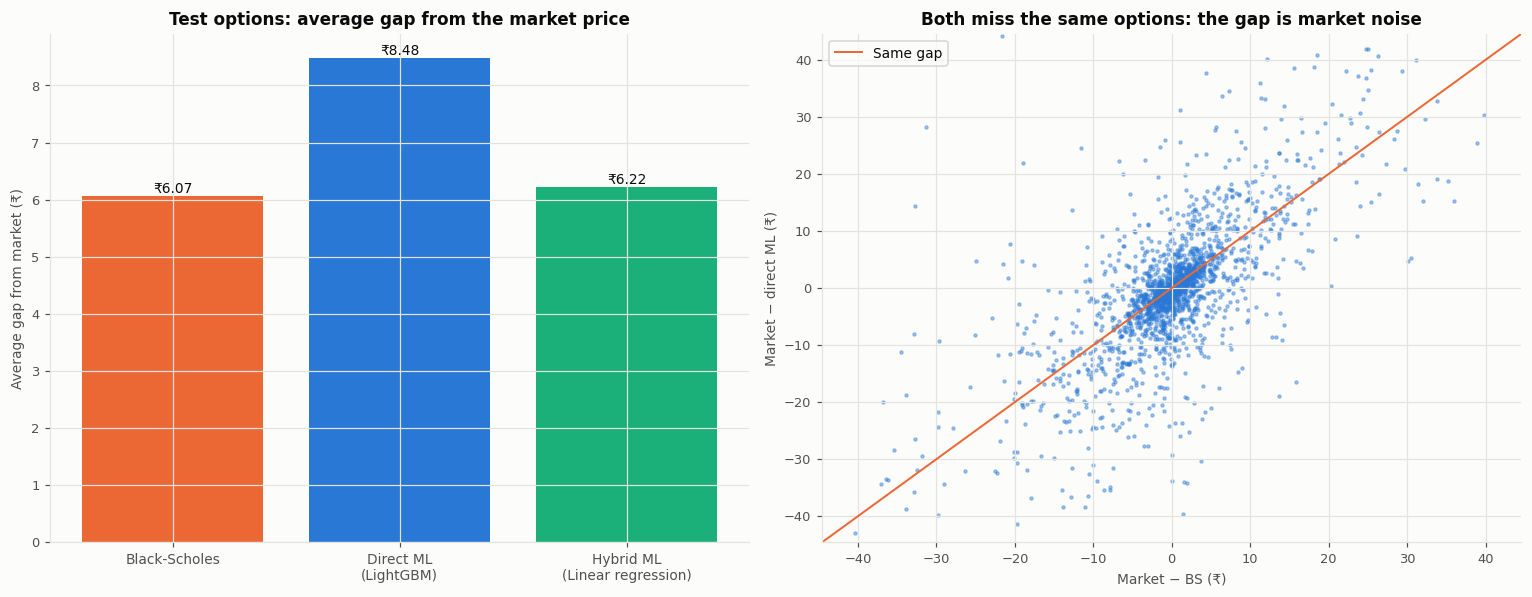

Link between the BS gap and the direct-ML gap on the same options: 0.73 (1 = they miss identically)


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
names = list(PRICERS)
ax[0].bar(range(3), [main.loc[n, "MAE (₹)"] for n in names], color=[ORANGE, BLUE, AQUA])
ax[0].set_xticks(range(3)); ax[0].set_xticklabels([n.replace(" (", "\n(") for n in names], fontsize=9)
ax[0].set_ylabel("Average gap from market (₹)"); ax[0].set_title("Test options: average gap from the market price")
for i, n in enumerate(names):
    ax[0].text(i, main.loc[n, "MAE (₹)"], f"₹{main.loc[n, 'MAE (₹)']:.2f}", ha="center", va="bottom")
d = test.Market_Price - test["Direct ML price"]; e = test.Market_Price - test.BS
ax[1].scatter(e, d, s=4, alpha=0.4, color=BLUE)
lim = np.percentile(np.abs(np.r_[d, e]), 99); ax[1].plot([-lim, lim], [-lim, lim], color=ORANGE, lw=1.3, label="Same gap")
ax[1].set_xlim(-lim, lim); ax[1].set_ylim(-lim, lim); ax[1].legend()
ax[1].set_xlabel("Market − BS (₹)"); ax[1].set_ylabel("Market − direct ML (₹)"); ax[1].set_title("Both miss the same options: the gap is market noise")
fig.tight_layout()
save_chart(fig, "01_ml_vs_bs_test")
GAP_LINK = float(np.corrcoef(d, e)[0, 1])
print(f"Link between the BS gap and the direct-ML gap on the same options: {GAP_LINK:.2f} (1 = they miss identically)")

## 6. Does it hold everywhere? By price, moneyness, call/put (test options)

In [8]:
test["Price fifth"] = pd.qcut(test.BS, 5, labels=["1 (cheapest)", "2", "3", "4", "5 (dearest)"])
seg = []
for by in ["Price fifth", "Moneyness band", "Option_Type"]:
    for grp, x in test.groupby(by, observed=True):
        r = {"Breakdown": by.replace("_", " "), "Group": grp, "Options": len(x)}
        for nm, col in PRICERS.items():
            r[f"MAE (₹): {nm}"] = (x.Market_Price - x[col]).abs().mean()
        r["Best"] = min(PRICERS, key=lambda nm: r[f"MAE (₹): {nm}"])
        seg.append(r)
seg = pd.DataFrame(seg)
display(seg.round(3))
print("Groups where BS is best:", (seg.Best == "Black-Scholes").sum(), "of", len(seg))

,Breakdown,Group,Options,MAE (₹): Black-Scholes,MAE (₹): Direct ML (LightGBM),MAE (₹): Hybrid ML (Linear regression),Best
0,Price fifth,1 (cheapest),400,1.558,2.532,1.792,Black-Scholes
1,Price fifth,2,400,2.111,3.433,2.151,Black-Scholes
2,Price fifth,3,400,4.168,6.276,4.293,Black-Scholes
3,Price fifth,4,400,7.422,11.329,7.433,Black-Scholes
4,Price fifth,5 (dearest),400,15.102,18.829,15.434,Black-Scholes
5,Moneyness band,At the money (±2%),167,6.138,8.428,6.167,Black-Scholes
6,Moneyness band,Far in the money (> 10%),612,9.874,12.888,10.160,Black-Scholes
7,Moneyness band,Far out of the money (< −10%),599,2.915,4.886,3.098,Black-Scholes
8,Moneyness band,In the money (2% to 10%),291,6.949,9.590,6.968,Black-Scholes
9,Moneyness band,Out of the money (−10% to −2%),331,3.953,5.883,3.958,Black-Scholes


Groups where BS is best: 12 of 12


## 6b. By stock: pricing on the test options
Same comparison, one row per stock (about 130 test options each). Task 1 found the stock makes no difference to the gap (p 0.49), so small wins either way are expected to be noise.

In [9]:
by_stock_price = test.groupby("Underlying").apply(lambda x: pd.Series({
    "Test options": len(x), **{f"MAE (₹): {nm}": (x.Market_Price - x[col]).abs().mean() for nm, col in PRICERS.items()}}),
    include_groups=False).reset_index().rename(columns={"Underlying": "Stock"})
by_stock_price["Best"] = by_stock_price[[f"MAE (₹): {nm}" for nm in PRICERS]].idxmin(axis=1).str.replace("MAE (₹): ", "", regex=False)
by_stock_price["Best ML vs BS (₹; + = ML closer)"] = by_stock_price["MAE (₹): Black-Scholes"] - by_stock_price[
    [f"MAE (₹): {nm}" for nm in PRICERS if nm != "Black-Scholes"]].min(axis=1)
display(by_stock_price.round(2))
print(f"BS best in {(by_stock_price.Best == 'Black-Scholes').sum()} of 15 stocks; where ML is best, by at most "
      f"₹{by_stock_price['Best ML vs BS (₹; + = ML closer)'].max():.2f} per option, on about 130 options: within noise "
      f"(Task 1: the stock makes no difference, p 0.49)")

,Stock,Test options,MAE (₹): Black-Scholes,MAE (₹): Direct ML (LightGBM),MAE (₹): Hybrid ML (Linear regression),Best,Best ML vs BS (₹; + = ML closer)
0,AXISBANK,127.0,6.54,9.44,6.55,Black-Scholes,-0.02
1,BHARTIARTL,140.0,5.40,7.44,5.53,Black-Scholes,-0.13
2,HDFCBANK,142.0,6.02,9.17,6.43,Black-Scholes,-0.41
3,HINDUNILVR,135.0,6.62,8.53,6.92,Black-Scholes,-0.30
4,ICICIBANK,147.0,6.40,9.08,6.51,Black-Scholes,-0.12
5,INFY,131.0,4.95,7.17,5.08,Black-Scholes,-0.13
6,ITC,119.0,4.84,7.25,5.05,Black-Scholes,-0.21
7,KOTAKBANK,148.0,5.66,10.24,5.89,Black-Scholes,-0.23
8,LT,114.0,6.90,7.80,7.22,Black-Scholes,-0.32
9,MARUTI,133.0,6.06,7.41,6.08,Black-Scholes,-0.01


BS best in 13 of 15 stocks; where ML is best, by at most ₹0.17 per option, on about 130 options: within noise (Task 1: the stock makes no difference, p 0.49)


## 7. Better than luck? The shuffled-correction test
Is the hybrid's correction learning anything real? Its correction model is refitted 20 times on shuffled gaps (any real pattern destroyed) and scored on the test. If the real correction is no better than the shuffled ones, it learned nothing.

In [10]:
cols = SETUPS["Hybrid"]
null_mae = []
for i in range(20):
    ys = np.random.default_rng(SEED + i).permutation(target(train, "Hybrid"))
    m = make_model(BEST["Hybrid"]).fit(train[cols], ys)
    null_mae.append(np.abs(to_price(test, "Hybrid", m.predict(test[cols])) - test.Market_Price).mean())
REAL_H = main.loc[f"Hybrid ML ({BEST['Hybrid']})", "MAE (₹)"]
P_LUCK = (np.sum(np.array(null_mae) <= REAL_H) + 1) / (len(null_mae) + 1)
print(f"Hybrid's test MAE ₹{REAL_H:.3f}; with shuffled corrections ₹{np.mean(null_mae):.3f} (range ₹{min(null_mae):.3f}–₹{max(null_mae):.3f}); "
      f"BS alone ₹{main.loc['Black-Scholes', 'MAE (₹)']:.3f}; p = {P_LUCK:.3f} (small p = the correction learned something real)")

Hybrid's test MAE ₹6.221; with shuffled corrections ₹6.128 (range ₹6.112–₹6.152); BS alone ₹6.072; p = 1.000 (small p = the correction learned something real)


## 8. What the models rely on
Permutation importance on the test options (seed 42): how much the direct model's average gap worsens when one input is shuffled. Big = the model relies on it.

In [11]:
pi = permutation_importance(fitted["Direct"], test[INPUTS], target(test, "Direct"), n_repeats=5, random_state=SEED,
                            scoring="neg_mean_absolute_error")
PLAIN = {"S/K": "How far the stock is from the strike", "ln(S/K)": "Same, on a log scale", "Time_to_Maturity": "Time left",
         "Volatility": "How much the stock swings", "Interest_Rate": "Interest rate", "Is call": "Call or put",
         "Vol x sqrt(T)": "Total expected swing until the end"}
drivers = pd.DataFrame({"Input": INPUTS, "In plain words": [PLAIN[c] for c in INPUTS],
                        "Worsening when shuffled (₹ per option)": pi.importances_mean * test.Strike.mean()}).sort_values(
                        "Worsening when shuffled (₹ per option)", ascending=False)
display(drivers.round(2))
print("These are exactly Black-Scholes' own inputs: the direct model has re-learned the formula, not found anything new.")

,Input,In plain words,Worsening when shuffled (₹ per option)
0,S/K,How far the stock is from the strike,126.11
5,Is call,Call or put,124.09
6,Vol x sqrt(T),Total expected swing until the end,43.76
1,ln(S/K),"Same, on a log scale",16.01
2,Time_to_Maturity,Time left,15.93
3,Volatility,How much the stock swings,7.84
4,Interest_Rate,Interest rate,2.50


These are exactly Black-Scholes' own inputs: the direct model has re-learned the formula, not found anything new.


## 9. Managing exposure: four hedging choices compared (decisions M8-14, M8-15)
**Hedging** = adding positions that gain when the option book loses. The book has two main risks (Task 1):
- **Stock-price risk (delta):** it moves like ₹22.6 lakh of shares.
- **Volatility risk (vega):** it gains ₹50,463 for every 1-point rise in volatility and loses the same for a fall. Option prices fall when markets calm down, even if stock prices don't move.

| Choice | What NovaFin does | Protects against | Doesn't protect against |
| --- | --- | --- | --- |
| **A. No hedge** | Nothing | — | Stock falls, volatility falls |
| **B. Delta hedge** | Sell shares worth the book's stock exposure (delta × spot), per stock; reset daily | Small stock moves | **Volatility** (shares don't react to it), big moves |
| **C. Delta + half vega hedge** | B, plus sell 1-year at-the-money calls on each stock to cancel **half** the book's volatility sensitivity; re-size the shares for those calls' delta | Stock moves; half the volatility risk | Half the volatility risk |
| **D. Delta + full vega hedge** | As C, but cancel **all** the volatility sensitivity | Stock moves and volatility | Very large moves; needs the most trading |

**Why shares can't hedge volatility:** a share's price doesn't depend on volatility, so when volatility changes the shares don't move and nothing offsets the options. Only other options can.

**How they're compared here (a stress view):** 21 scenarios (every stock moves −10%, −5%, −1%, 0, +1%, +5%, +10%, combined with volatility −5, 0 or +5 points), each option repriced exactly with BS. For each choice: the **worst loss**, the typical swing, what must be traded, the cost of trading it, and the daily time decay.

**Assumptions:** the hedge calls are priced at BS (strike = the stock's typical spot, 1 year, the stock's typical volatility). Share trades cost 0.1% (delivery charges). Option trades cost 1% of the premium (charges + bid–ask, an assumption). All choices are reset daily.

Step 9c adds **how likely** losses are, what running each hedge costs, and the written-book check; step 9d gives the choice rule.

In [12]:
full = load_options().merge(t1[["Option ID", "Delta", "BS price (₹, ours)", "Vega (₹ per +1 volatility point)", "Theta (₹ per day)"]],
                            left_on="Option_ID", right_on="Option ID")
is_call = (full.Option_Type == "Call").to_numpy()
S, K, T, V, R = (full[c].to_numpy() for c in ["Spot", "Strike", "Time_to_Maturity", "Volatility", "Interest_Rate"])
BASE = bs_price(S, K, T, V, R, is_call)
STOCKS = full.Underlying.to_numpy()
SHARE_COST, OPTION_COST = 0.001, 0.01                      # assumptions: share charges 0.1%; option charges + bid–ask 1% of premium

# The hedge instrument per stock: a 1-year at-the-money call at the stock's typical spot, volatility and rate
inst = full.groupby("Underlying").agg(s0=("Spot", "median"), v0=("Volatility", "median"), r0=("Interest_Rate", "median"),
                                      book_vega=("Vega (₹ per +1 volatility point)", "sum"), book_theta=("Theta (₹ per day)", "sum"))
inst["book_exposure"] = (full.Delta * full.Spot).groupby(full.Underlying).sum()
ig = greeks(inst.s0.to_numpy(), inst.s0.to_numpy(), np.ones(len(inst)), inst.v0.to_numpy(), inst.r0.to_numpy(), np.ones(len(inst), bool))
inst["h_price"] = bs_price(inst.s0.to_numpy(), inst.s0.to_numpy(), np.ones(len(inst)), inst.v0.to_numpy(), inst.r0.to_numpy(), np.ones(len(inst), bool))
inst["h_delta"], inst["h_vega"], inst["h_theta"] = ig.Delta.to_numpy(), ig.Vega_per_vol_point.to_numpy(), ig.Theta_per_day.to_numpy()

CHOICES = {"A. No hedge": (False, 0.0), "B. Delta hedge": (True, 0.0), "C. Delta + half vega hedge": (True, 0.5),
           "D. Delta + full vega hedge": (True, 1.0)}


def hedge_positions(delta_on: bool, vega_share: float) -> pd.DataFrame:
    """Per stock: hedge calls to hold (negative = sell) and the ₹ of shares to hold (negative = sell)."""
    h = pd.DataFrame(index=inst.index)
    h["Calls (units)"] = -vega_share * inst.book_vega / inst.h_vega
    h["Shares (₹)"] = -(inst.book_exposure + h["Calls (units)"] * inst.h_delta * inst.s0) if delta_on else 0.0
    return h


def scenario_change(pos: pd.DataFrame, move: float, dvol: float) -> pd.Series:
    """₹ change per stock of book + hedge when every stock moves by `move` and volatility by `dvol` (0.05 = 5 points)."""
    opt = pd.Series(bs_price(S * (1 + move), K, T, np.maximum(V + dvol, 0.01), R, is_call) - BASE).groupby(STOCKS).sum()
    calls = pos["Calls (units)"] * (bs_price((inst.s0 * (1 + move)).to_numpy(), inst.s0.to_numpy(), np.ones(len(inst)),
                                             np.maximum(inst.v0 + dvol, 0.01).to_numpy(), inst.r0.to_numpy(), np.ones(len(inst), bool)) - inst.h_price)
    return opt + calls + pos["Shares (₹)"] * move


MOVES, VOLS = [-0.10, -0.05, -0.01, 0.0, 0.01, 0.05, 0.10], [-0.05, 0.0, 0.05]
POS = {c: hedge_positions(*v) for c, v in CHOICES.items()}
grid = []
for mv in MOVES:
    for dv in VOLS:
        row = {"Stocks move": f"{mv:+.0%}", "Volatility change (points)": f"{dv * 100:+.0f}"}
        for c in CHOICES:
            row[c] = scenario_change(POS[c], mv, dv).sum()
        grid.append(row)
grid = pd.DataFrame(grid)
print("Change in the book's value (₹) in each scenario:"); display(grid.round(0))

summary = []
for c in CHOICES:
    p = POS[c]; vals = grid[c]
    worst = grid.loc[vals.idxmin()]
    summary.append({"Choice": c, "Worst result (₹)": vals.min(), "Worst scenario": f"stocks {worst['Stocks move']}, volatility {worst['Volatility change (points)']} points",
                    "Best result (₹)": vals.max(), "Typical swing (₹, average size of change)": vals.abs().mean(),
                    "Scenarios that lose": int((vals < 0).sum()),
                    "Shares to trade (₹)": p["Shares (₹)"].abs().sum(), "Calls to sell (units)": -p["Calls (units)"].sum(),
                    "Premium received for calls sold (₹)": (-p["Calls (units)"] * inst.h_price).sum(),
                    "Total trading (₹: shares + calls sold)": p["Shares (₹)"].abs().sum() + (p["Calls (units)"].abs() * inst.h_price).sum(),
                    "Total trading ÷ book value": (p["Shares (₹)"].abs().sum() + (p["Calls (units)"].abs() * inst.h_price).sum()) / float(full.Market_Price.sum()),
                    "Upfront trading cost (₹)": p["Shares (₹)"].abs().sum() * SHARE_COST + (p["Calls (units)"].abs() * inst.h_price).sum() * OPTION_COST,
                    "Time decay (₹ a day)": inst.book_theta.sum() + (p["Calls (units)"] * inst.h_theta).sum(),
                    "Volatility sensitivity left (₹ per point)": inst.book_vega.sum() + (p["Calls (units)"] * inst.h_vega).sum()})
choices = pd.DataFrame(summary)
display(choices.round(0))

Change in the book's value (₹) in each scenario:


,Stocks move,Volatility change (points),A. No hedge,B. Delta hedge,C. Delta + half vega hedge,D. Delta + full vega hedge
0,-10%,-5,-320084.0,-94339.0,-29159.0,36021.0
1,-10%,+0,-90621.0,135124.0,78158.0,21192.0
2,-10%,+5,160217.0,385962.0,206450.0,26939.0
3,-5%,-5,-318292.0,-205419.0,-91662.0,22096.0
4,-5%,+0,-79948.0,32925.0,19169.0,5413.0
5,-5%,+5,180001.0,292873.0,151892.0,10911.0
6,-1%,-5,-261278.0,-238704.0,-113088.0,12528.0
7,-1%,+0,-21289.0,1286.0,753.0,220.0
8,-1%,+5,240722.0,263297.0,135526.0,7755.0
9,+0%,-5,-239685.0,-239685.0,-114582.0,10520.0


,Choice,Worst result (₹),Worst scenario,Best result (₹),"Typical swing (₹, average size of change)",Scenarios that lose,Shares to trade (₹),Calls to sell (units),Premium received for calls sold (₹),Total trading (₹: shares + calls sold),Total trading ÷ book value,Upfront trading cost (₹),Time decay (₹ a day),Volatility sensitivity left (₹ per point)
0,A. No hedge,-320084.0,"stocks -10%, volatility -5 points",591833.0,209233.0,9,0.0,-0.0,0.0,0.0,0.0,0.0,-2068.0,50463.0
1,B. Delta hedge,-239685.0,"stocks +0%, volatility -5 points",385962.0,179162.0,7,2257447.0,-0.0,0.0,2257447.0,1.0,2257.0,-2068.0,50463.0
2,C. Delta + half vega hedge,-114582.0,"stocks +0%, volatility -5 points",206450.0,91420.0,7,2196997.0,3813.0,867022.0,3064019.0,2.0,10867.0,-603.0,25232.0
3,D. Delta + full vega hedge,0.0,"stocks +0%, volatility +0 points",42593.0,13565.0,0,6651441.0,7625.0,1734045.0,8385485.0,4.0,23992.0,862.0,0.0


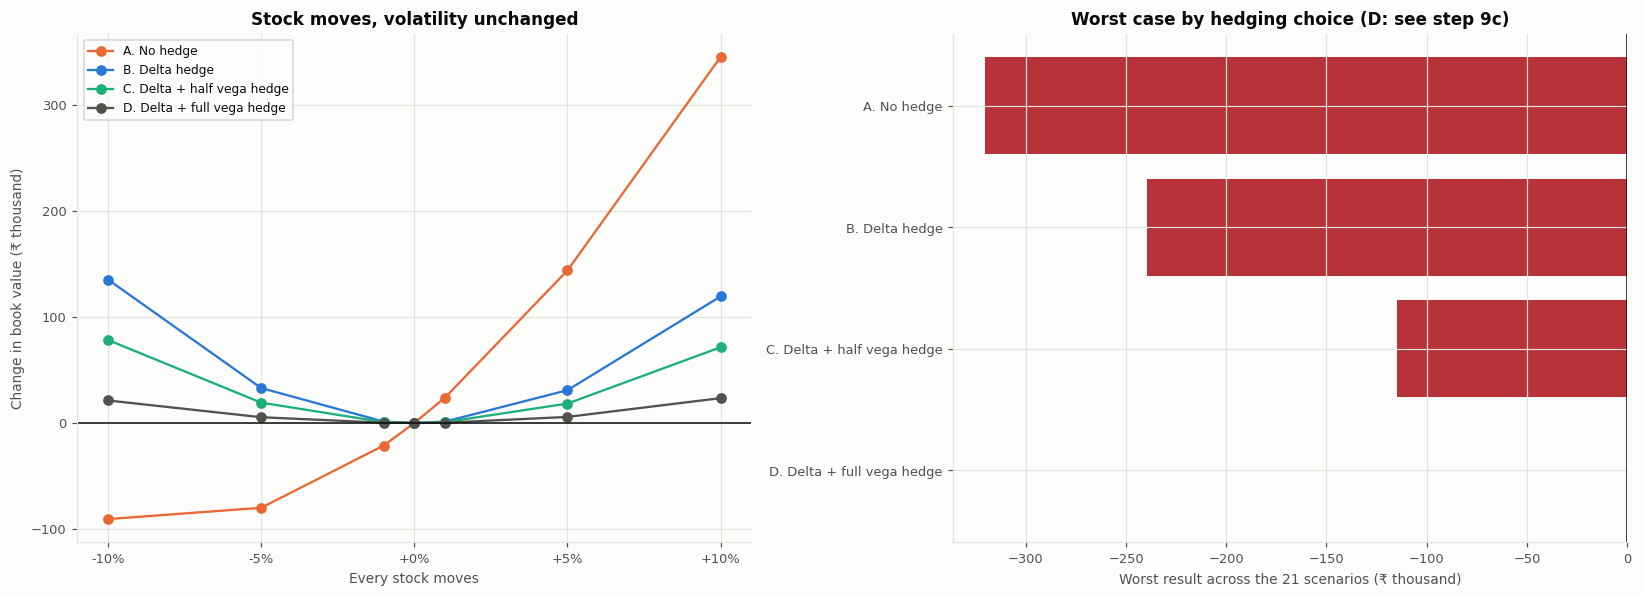

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
cols_c = [ORANGE, BLUE, AQUA, INK_2]
for c, col in zip(CHOICES, cols_c):
    g0 = grid[grid["Volatility change (points)"] == "+0"]
    ax[0].plot(MOVES, g0[c] / 1e3, marker="o", color=col, label=c)
ax[0].axhline(0, color=INK, lw=1); ax[0].set_xlabel("Every stock moves"); ax[0].set_ylabel("Change in book value (₹ thousand)")
ax[0].xaxis.set_major_locator(plt.MultipleLocator(0.05)); ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}")); ax[0].set_title("Stock moves, volatility unchanged"); ax[0].legend(fontsize=8)
y = np.arange(len(choices))
ax[1].barh(y, choices["Worst result (₹)"] / 1e3, color=[LOSS if v < 0 else GAIN for v in choices["Worst result (₹)"]])
ax[1].set_yticks(y); ax[1].set_yticklabels(choices.Choice); ax[1].invert_yaxis(); ax[1].axvline(0, color=INK, lw=1)
ax[1].set_xlabel("Worst result across the 21 scenarios (₹ thousand)"); ax[1].set_title("Worst case by hedging choice (D: see step 9c)")
fig.tight_layout()
save_chart(fig, "02_hedging_choices")

## 9c. How likely is a loss, how often to re-hedge, what it ties up (decisions M8-17, M8-20)
Step 9's scenarios say how bad things *can* get. Here: **how often** each choice loses and how big a bad day or month is, from 100,000 simulated trading days (seed 42).

**How a day is simulated** (assumptions):
- Each stock moves by a random % with its typical daily swing (median volatility ÷ √252 ≈ 1.5%); stocks move together with correlation 0.4 (the real-market figure used in Module 6).
- Volatility changes by about 1 point on a typical day and tends to rise when stocks fall (correlation −0.5). Also checked at 0.5 and 2 points.
- One day of time decay passes; the hedge is reset every morning.
- ₹ change = delta × move + ½ × gamma × move² + vega × volatility change + theta (checked against exact repricing below).

**Is the hedge's share purchase a cost?** No. The shares are a holding (their value moves with the market and they can be sold back). The costs are the trading charges, the cash tied up, and the daily re-hedging.

In [14]:
gk_all = greeks(S, K, T, V, R, is_call)
book_g = pd.DataFrame({"E": (full.Delta * full.Spot).to_numpy(), "G": gk_all.Gamma.to_numpy() * S ** 2,
                       "Vg": gk_all.Vega_per_vol_point.to_numpy(), "Th": gk_all.Theta_per_day.to_numpy()}).groupby(STOCKS).sum().loc[inst.index]
h_gamma = greeks(inst.s0.to_numpy(), inst.s0.to_numpy(), np.ones(len(inst)), inst.v0.to_numpy(), inst.r0.to_numpy(), np.ones(len(inst), bool)).Gamma.to_numpy()
H_E = (inst.h_delta * inst.s0).to_numpy(); H_G = h_gamma * inst.s0.to_numpy() ** 2


def day_change(pos: pd.DataFrame, r: np.ndarray, dv: np.ndarray, sign: float = 1.0) -> np.ndarray:
    """₹ change for each simulated day: book × sign (+1 owned, −1 written) + hedge calls + hedge shares.
    r: stock moves (days × stocks); dv: volatility change in points (days)."""
    n = pos["Calls (units)"].to_numpy(); sh = pos["Shares (₹)"].to_numpy()
    book = sign * (r * book_g.E.to_numpy() + 0.5 * r ** 2 * book_g.G.to_numpy() + np.outer(dv, book_g.Vg.to_numpy()) + book_g.Th.to_numpy())
    calls = n * (r * H_E + 0.5 * r ** 2 * H_G + np.outer(dv, inst.h_vega.to_numpy()) + inst.h_theta.to_numpy())
    return (book + calls + r * sh).sum(axis=1)


# Check the estimate against exact repricing (step 9's scenarios have no time decay, so it is taken out here)
for mv, dvv in [(-0.05, 0.0), (0.0, -0.05), (-0.05, 0.05)]:
    est = day_change(POS["A. No hedge"], np.full((1, len(inst)), mv), np.array([dvv * 100]))[0] - book_g.Th.sum()
    print(f"Check — stocks {mv:+.0%}, volatility {dvv * 100:+.0f} points: estimate ₹{est:+,.0f}, exact ₹{scenario_change(POS['A. No hedge'], mv, dvv).sum():+,.0f}")

N_DAYS, CORR, VOL_SD, VOL_CORR = 100_000, 0.4, 1.0, -0.5
sim_rng = np.random.default_rng(SEED)
sim_mkt = sim_rng.standard_normal(N_DAYS); sim_own = sim_rng.standard_normal((N_DAYS, len(inst))); sim_vol = sim_rng.standard_normal(N_DAYS)
R_SIM = (np.sqrt(CORR) * sim_mkt[:, None] + np.sqrt(1 - CORR) * sim_own) * (inst.v0 / np.sqrt(252)).to_numpy()
DV_SIM = VOL_CORR * sim_mkt + np.sqrt(1 - VOL_CORR ** 2) * sim_vol          # in points, typical size 1


def loss_row(c: str, sign: float = 1.0, vol_sd: float = VOL_SD) -> dict:
    """How often and how badly one hedging choice loses (owned book: sign +1; written: −1, with the hedge flipped)."""
    pos = POS[c] * sign
    days = day_change(pos, R_SIM, DV_SIM * vol_sd, sign)
    month = days[: (N_DAYS // 21) * 21].reshape(-1, 21).sum(axis=1)             # 21 trading days, re-hedged daily
    v95, v99 = -np.percentile(days, 5), -np.percentile(days, 1)
    return {"Choice": c, "Chance of a losing day": (days < 0).mean(), "Average day (₹)": days.mean(),
            "1-in-20 bad day: loss (₹)": v95, "1-in-100 bad day: loss (₹)": v99, "Chance of a losing month": (month < 0).mean(),
            "1-in-20 bad month: loss (₹)": -np.percentile(month, 5)}


prob = pd.DataFrame([loss_row(c) for c in CHOICES])
print("OWNED book (main view, M8-05):"); display(prob.round(3))
prob_w = pd.DataFrame([loss_row(c, sign=-1.0) for c in CHOICES])
print("Check — if NovaFin had WRITTEN (sold) these options (M8-20): every risk flips"); display(prob_w.round(3))
sens = pd.DataFrame([{"Typical daily volatility change (points)": v, **{c: loss_row(c, vol_sd=v)["1-in-100 bad day: loss (₹)"] for c in CHOICES}}
                     for v in [0.5, 1.0, 2.0]])
print("Check — 1-in-100 bad-day loss (₹) if volatility moves less or more than assumed:")
display(sens.set_index("Typical daily volatility change (points)").round(0))
print("D shows no loss on any day. That is not real protection: options on the same 'stock' here carry different volatilities and spot "
      "prices (Task 1, M8-18), so selling one 1-year call per stock against them creates a gain no real market would allow. "
      "D is therefore flagged as unreliable on this data and left out of the choice rule.")

Check — stocks -5%, volatility +0 points: estimate ₹-80,935, exact ₹-79,948
Check — stocks +0%, volatility -5 points: estimate ₹-252,316, exact ₹-239,685
Check — stocks -5%, volatility +5 points: estimate ₹+171,381, exact ₹+180,001


OWNED book (main view, M8-05):


,Choice,Chance of a losing day,Average day (₹),1-in-20 bad day: loss (₹),1-in-100 bad day: loss (₹),Chance of a losing month,1-in-20 bad month: loss (₹)
0,A. No hedge,0.491,1001.575,71903.728,102738.386,0.457,316311.483
1,B. Delta hedge,0.495,1057.472,81275.101,114853.641,0.467,357559.127
2,C. Delta + half vega hedge,0.485,1212.226,39928.395,56653.453,0.418,164504.247
3,D. Delta + full vega hedge,0.000,1366.981,-1041.256,-987.433,0.000,-26450.418


Check — if NovaFin had WRITTEN (sold) these options (M8-20): every risk flips


,Choice,Chance of a losing day,Average day (₹),1-in-20 bad day: loss (₹),1-in-100 bad day: loss (₹),Chance of a losing month,1-in-20 bad month: loss (₹)
0,A. No hedge,0.509,-1001.575,74299.029,104540.393,0.543,363312.537
1,B. Delta hedge,0.505,-1057.472,84606.641,120195.048,0.533,404373.176
2,C. Delta + half vega hedge,0.515,-1212.226,43023.451,60949.431,0.582,216219.106
3,D. Delta + full vega hedge,1.000,-1366.981,2028.056,2653.935,1.000,31446.176


Check — 1-in-100 bad-day loss (₹) if volatility moves less or more than assumed:


,A. No hedge,B. Delta hedge,C. Delta + half vega hedge,D. Delta + full vega hedge
Typical daily volatility change (points),,,,
0.5,55327.0,56643.0,27573.0,-987.0
1.0,102738.0,114854.0,56653.0,-987.0
2.0,213045.0,231587.0,115070.0,-987.0


D shows no loss on any day. That is not real protection: options on the same 'stock' here carry different volatilities and spot prices (Task 1, M8-18), so selling one 1-year call per stock against them creates a gain no real market would allow. D is therefore flagged as unreliable on this data and left out of the choice rule.


In [15]:
# Running each hedge: what is traded on day 1, the cash it ties up, and the daily re-hedging
run_rows = []
for c in CHOICES:
    pos = POS[c]
    if c == "A. No hedge":
        daily = 0.0
    else:
        # After a move r the hedge's stock exposure is off by (book gamma + calls' gamma) × r: next morning's share trade
        g_tot = book_g.G.to_numpy() + pos["Calls (units)"].to_numpy() * H_G
        daily = float(np.abs(R_SIM[:20_000] * g_tot).sum(axis=1).mean())
    bought, sold = pos["Shares (₹)"].clip(lower=0).sum(), -pos["Shares (₹)"].clip(upper=0).sum()
    prem = float((-pos["Calls (units)"] * inst.h_price).sum())
    run_rows.append({"Choice": c, "Day 1: shares bought (₹)": bought, "Day 1: shares sold (₹)": sold,
                     "Day 1: calls sold (units)": -pos["Calls (units)"].sum(), "Day 1: premium received (₹)": prem,
                     "Cash tied up (₹: bought − sold − premium)": bought - sold - prem,
                     "Day 1: trading charges (₹)": choices.set_index("Choice").loc[c, "Upfront trading cost (₹)"],
                     "How often reset": "—" if c == "A. No hedge" else "Shares every day; calls when the book changes",
                     "Shares traded on a typical day to re-hedge (₹)": daily, "Re-hedging charges a year (₹: 252 days × 0.1%)": daily * 252 * SHARE_COST})
running = pd.DataFrame(run_rows)
display(running.round(0))
print("Positions sold short (shares in B, calls in C and D) also need exchange margin, which is not modelled.")

,Choice,Day 1: shares bought (₹),Day 1: shares sold (₹),Day 1: calls sold (units),Day 1: premium received (₹),Cash tied up (₹: bought − sold − premium),Day 1: trading charges (₹),How often reset,Shares traded on a typical day to re-hedge (₹),Re-hedging charges a year (₹: 252 days × 0.1%)
0,A. No hedge,0.0,-0.0,-0.0,0.0,0.0,0.0,—,0.0,0.0
1,B. Delta hedge,0.0,2257447.0,-0.0,0.0,-2257447.0,2257.0,Shares every day; calls when the book changes,307716.0,77544.0
2,C. Delta + half vega hedge,2196997.0,-0.0,3813.0,867022.0,1329975.0,10867.0,Shares every day; calls when the book changes,180552.0,45499.0
3,D. Delta + full vega hedge,6651441.0,-0.0,7625.0,1734045.0,4917396.0,23992.0,Shares every day; calls when the book changes,53389.0,13454.0


Positions sold short (shares in B, calls in C and D) also need exchange margin, which is not modelled.


## 9d. The choice rule, and the recommended hedge by stock (decision M8-15, revised)
**Rule:** the Board sets the most it accepts losing on a **1-in-100 bad day** (as a share of the book's value). Pick the choice with the **least trading** that stays within it. D is left out (step 9c). B is never picked: it loses more than no hedge on bad days and costs more.

In [16]:
BOOK = float(full.Market_Price.sum())
P = prob.set_index("Choice").join(choices.set_index("Choice")[["Total trading (₹: shares + calls sold)"]])
USABLE = ["A. No hedge", "B. Delta hedge", "C. Delta + half vega hedge"]
LIMITS = [0.02, 0.03, 0.04, 0.05, 0.06]
rule = []
for L in LIMITS:
    ok = P.loc[USABLE][P.loc[USABLE, "1-in-100 bad day: loss (₹)"] <= L * BOOK]
    pick = ok.sort_values("Total trading (₹: shares + calls sold)").index[0] if len(ok) else "None of A–C (would need a fuller vega hedge, not reliable on this data)"
    rule.append({"Board's limit: most it accepts losing on a 1-in-100 bad day": f"{L:.0%} of the book (₹{L * BOOK:,.0f})",
                 "Choice with the least trading within it": pick})
rule = pd.DataFrame(rule)
display(rule)
RISK_LIMIT = 0.04            # agreed default (user, 22 Nov 2026; M8-15): a 1-in-100 bad day should cost at most 4% of the book → C
RECOMMENDED = rule.iloc[LIMITS.index(RISK_LIMIT)]["Choice with the least trading within it"]
print(f"Recommended at a {RISK_LIMIT:.0%} limit (₹{RISK_LIMIT * BOOK:,.0f}): {RECOMMENDED}")

pos_r = POS[RECOMMENDED]
hedge_by_stock = pd.DataFrame({"Stock": inst.index, "Options": full.groupby("Underlying").size().values,
    "Book value (₹)": full.groupby("Underlying").Market_Price.sum().values, "Stock-equivalent exposure (₹)": inst.book_exposure.values,
    "Volatility sensitivity (₹ per point)": inst.book_vega.values, "Time decay (₹ a day)": inst.book_theta.values,
    "Unhedged: stocks −5% (₹)": [scenario_change(POS["A. No hedge"], -0.05, 0)[u] for u in inst.index],
    "Unhedged: volatility −5 points (₹)": [scenario_change(POS["A. No hedge"], 0, -0.05)[u] for u in inst.index],
    f"{RECOMMENDED}: calls to sell (units)": -pos_r["Calls (units)"].values,
    f"{RECOMMENDED}: shares to buy (+) or sell (−) (₹)": pos_r["Shares (₹)"].values,
    f"{RECOMMENDED}: worst of the 21 scenarios (₹)": [min(scenario_change(pos_r, mv, dv)[u] for mv in MOVES for dv in VOLS) for u in inst.index]})
display(hedge_by_stock.round(0))
HEDGE_TOTAL = float(POS["B. Delta hedge"]["Shares (₹)"].sum())
scen = grid
print("Share amounts are in ₹: options on the same stock carry different spot prices in this data (Task 1), so share counts are not meaningful.")

,Board's limit: most it accepts losing on a 1-in-100 bad day,Choice with the least trading within it
0,"2% of the book (₹38,791)","None of A–C (would need a fuller vega hedge, n..."
1,"3% of the book (₹58,186)",C. Delta + half vega hedge
2,"4% of the book (₹77,581)",C. Delta + half vega hedge
3,"5% of the book (₹96,977)",C. Delta + half vega hedge
4,"6% of the book (₹116,372)",A. No hedge


Recommended at a 4% limit (₹77,581): C. Delta + half vega hedge


,Stock,Options,Book value (₹),Stock-equivalent exposure (₹),Volatility sensitivity (₹ per point),Time decay (₹ a day),Unhedged: stocks −5% (₹),Unhedged: volatility −5 points (₹),C. Delta + half vega hedge: calls to sell (units),C. Delta + half vega hedge: shares to buy (+) or sell (−) (₹),C. Delta + half vega hedge: worst of the 21 scenarios (₹)
0,AXISBANK,657,128918.0,165994.0,3413.0,-135.0,-6169.0,-16222.0,255.0,134536.0,-7758.0
1,BHARTIARTL,665,123902.0,139310.0,3233.0,-135.0,-4819.0,-15353.0,256.0,145422.0,-7335.0
2,HDFCBANK,668,135161.0,192185.0,3391.0,-142.0,-7431.0,-16048.0,254.0,105674.0,-7633.0
3,HINDUNILVR,695,140142.0,159484.0,3553.0,-146.0,-5690.0,-16915.0,264.0,153492.0,-8099.0
4,ICICIBANK,698,133315.0,137763.0,3529.0,-134.0,-4659.0,-16721.0,265.0,175228.0,-7985.0
5,INFY,702,135946.0,167624.0,3563.0,-151.0,-5973.0,-16953.0,260.0,146889.0,-8120.0
6,ITC,643,127560.0,168374.0,3235.0,-131.0,-6322.0,-15289.0,230.0,118510.0,-7281.0
7,KOTAKBANK,676,128614.0,128479.0,3504.0,-136.0,-4158.0,-16712.0,268.0,181433.0,-8028.0
8,LT,639,125881.0,198454.0,3290.0,-142.0,-7805.0,-15537.0,241.0,92061.0,-7381.0
9,MARUTI,671,124289.0,167003.0,3307.0,-150.0,-6171.0,-15761.0,257.0,124039.0,-7562.0


Share amounts are in ₹: options on the same stock carry different spot prices in this data (Task 1), so share counts are not meaningful.


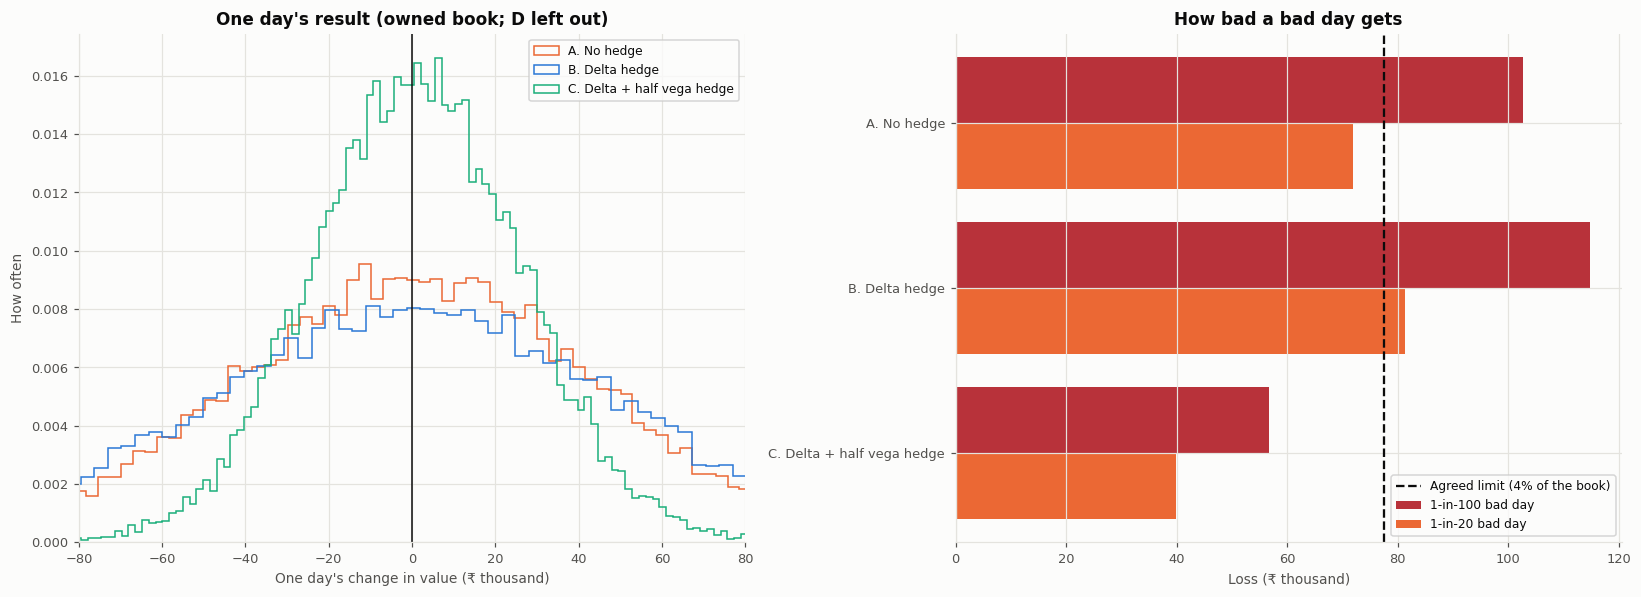

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for c, col in zip(CHOICES, [ORANGE, BLUE, AQUA, INK_2]):
    if c == "D. Delta + full vega hedge":
        continue
    one_day = day_change(POS[c], R_SIM[:20_000], DV_SIM[:20_000])
    ax[0].hist(one_day / 1e3, bins=120, histtype="step", color=col, lw=1.6, label=c, density=True)
ax[0].axvline(0, color=INK, lw=1); ax[0].set_xlim(-80, 80)
ax[0].set_xlabel("One day's change in value (₹ thousand)"); ax[0].set_ylabel("How often"); ax[0].set_title("One day's result (owned book; D left out)")
ax[0].legend(fontsize=8)
pu = prob.set_index("Choice").loc[USABLE]
y = np.arange(len(pu))
ax[1].barh(y - 0.2, pu["1-in-100 bad day: loss (₹)"] / 1e3, 0.4, color=LOSS, label="1-in-100 bad day")
ax[1].barh(y + 0.2, pu["1-in-20 bad day: loss (₹)"] / 1e3, 0.4, color=ORANGE, label="1-in-20 bad day")
ax[1].axvline(RISK_LIMIT * BOOK / 1e3, color=INK, ls="--", label=f"Agreed limit ({RISK_LIMIT:.0%} of the book)")
ax[1].set_yticks(y); ax[1].set_yticklabels(pu.index); ax[1].invert_yaxis(); ax[1].set_xlabel("Loss (₹ thousand)")
ax[1].set_title("How bad a bad day gets"); ax[1].legend(fontsize=8)
fig.tight_layout()
save_chart(fig, "03_hedge_loss_chances")

## 9e. What goes to Module 9: protecting the capital Module 9 puts into equities (decision M8-21)
"Derivatives hedging" in Module 9 means protecting NovaFin's **own** exposures, not only this option book. The largest one is the money Module 9 may put into equities (Module 6: about 15.6% a year, but **a 20% crash costs ₹20 crore per ₹100 crore** and diversification can't remove it).

**The tool: a put option on the equity holding** (the right to sell it at a set floor). Bought once a year, it caps the year's loss at the floor plus its cost. Priced with Black-Scholes (Task 1) using Module 6's real-market yearly swing (19.4%) and the 6.8% risk-free rate.

| Floor | Means |
| --- | --- |
| 100% | No loss below today's value (most expensive) |
| 90% | Loss capped at 10% plus the cost |
| 80% | Loss capped at 20% plus the cost (cheapest; only protects against crashes) |

**Assumptions:** one 1-year put on the whole equity holding (like an index put); BS price at 19.4% volatility (real markets often charge more for puts: shown as a check at 25%); 1% of premium in trading costs.

In [18]:
K6B = json.loads((PROJECT_ROOT / "module_06_portfolio_optimization" / "outputs" / "partB" / "key_numbers.json").read_text(encoding="utf-8"))
K6A = json.loads((PROJECT_ROOT / "module_06_portfolio_optimization" / "outputs" / "partA" / "key_numbers.json").read_text(encoding="utf-8"))
EQ_VOL, RF = K6B["vol_data_vs_real"]["Equal weight"][1], K6A["risk_free"]          # 19.4% real-market swing; 6.8%
EQ_RET = K6A["strategies"]["Equal weight"]["CAGR"]                                  # 15.6% a year
put_rows = []
for floor in [1.00, 0.90, 0.80]:
    for vol, lab in [(EQ_VOL, "Module 6 swing"), (0.25, "Check: puts priced dearer")]:
        prem = float(bs_price(100.0, 100 * floor, 1.0, vol, RF, False)) * (1 + OPTION_COST)       # ₹ crore per ₹100 crore, with 1% costs
        row = {"Floor": f"{floor:.0%}", "Priced at": f"{lab} ({vol:.1%})", "Cost a year (₹ crore per ₹100 crore)": prem,
               "Normal year: equity return after the cost (% a year)": 100 * EQ_RET - prem}
        for crash in [-0.10, -0.20, -0.30]:
            row[f"Stocks {crash:+.0%}: result (₹ crore per ₹100 crore)"] = max(100 * crash, 100 * (floor - 1)) - prem
        put_rows.append(row)
protect = pd.DataFrame(put_rows)
display(protect.round(2))
P90 = protect[(protect.Floor == "90%") & protect["Priced at"].str.startswith("Module 6")].iloc[0]
print(f"Unprotected, a 20% crash costs ₹20 crore per ₹100 crore. A 90% floor costs ₹{P90['Cost a year (₹ crore per ₹100 crore)']:.2f} crore a year, "
      f"cuts that to ₹{-P90['Stocks -20%: result (₹ crore per ₹100 crore)']:.1f} crore, and leaves a normal year at "
      f"{P90['Normal year: equity return after the cost (% a year)']:.1f}% instead of {100 * EQ_RET:.1f}%.")

# Module 7's order timing applied to Module 9's own equity trades (Module 6's measured turnover)
TURNOVER = K6A["strategies"]["Equal weight"]["Turnover a month"] * 12
print(f"Link to Module 7: equal-weight turnover is {TURNOVER:.2f}× a year, so timing those orders saves about "
      f"{TURNOVER * 1315 / 1e7 * 100:.3f}% a year of the equity money (₹{TURNOVER * 1315 * 100 / 1e5:.2f} lakh per ₹100 crore): real but small.")

hc_ = choices.set_index("Choice"); run_ = running.set_index("Choice"); BOOKV = float(full.Market_Price.sum())
m9_rows = []
for floor in ["100%", "90%", "80%"]:
    r = protect[(protect.Floor == floor) & protect["Priced at"].str.startswith("Module 6")].iloc[0]
    m9_rows.append({"Category": f"Derivatives hedging: protect equity money ({floor} floor put)",
                    "What NovaFin would put money into": f"A 1-year put on the equity holding with a {floor} floor (per ₹100 crore of equities)",
                    "Return per ₹ deployed (% a year)": round(-r["Cost a year (₹ crore per ₹100 crore)"], 2),
                    "Return range (% a year)": f"Cost {r['Cost a year (₹ crore per ₹100 crore)']:.2f}% of the protected amount; up to {protect[(protect.Floor == floor) & ~protect['Priced at'].str.startswith('Module 6')].iloc[0]['Cost a year (₹ crore per ₹100 crore)']:.2f}% if puts are priced dearer",
                    "Bad-year result per ₹ (% a year)": round(r["Stocks -20%: result (₹ crore per ₹100 crore)"], 2),
                    "How the bad year is defined": "Equities −20% (Module 6's crash scenario), protected holding incl. the put's cost; unprotected −20%",
                    "Capacity (₹ crore)": "Sized to the equity allocation", "Evidence strength": "Medium: standard BS pricing; volatility from Module 6's real-market estimate",
                    "How fast the money can come back": "Premium is spent each year; the protection lasts the year",
                    "Data gap or assumption": "No market prices for index puts in the data; BS at 19.4% (checked at 25%); 1% trading cost",
                    "Controls": "Buy yearly with the equity allocation; floor set by the Board's crash limit",
                    "Detail tab": "T2 protect equity money", "Detail column(s)": "Floor, Cost a year, Stocks −20%: result", "Decision": "M8-21"})
m9_rows.append({"Category": "Derivatives hedging: the option book (choice C)", "What NovaFin would put money into":
                    f"Delta + half vega hedge of the ₹{BOOKV / 1e5:.1f} lakh option book (one unit of each option)",
                "Return per ₹ deployed (% a year)": round(-100 * (run_.loc[RECOMMENDED, "Day 1: trading charges (₹)"] + run_.loc[RECOMMENDED, "Re-hedging charges a year (₹: 252 days × 0.1%)"]) / BOOKV, 2),
                "Return range (% a year)": "Cost of running the hedge as a share of the book's value (first year)",
                "Bad-year result per ₹ (% a year)": round(-100 * prob.set_index("Choice").loc[RECOMMENDED, "1-in-100 bad day: loss (₹)"] / BOOKV, 2),
                "How the bad year is defined": f"1-in-100 bad day with the hedge (unhedged: {-100 * prob.iloc[0]['1-in-100 bad day: loss (₹)'] / BOOKV:.1f}% of the book)",
                "Capacity (₹ crore)": round(run_.loc[RECOMMENDED, "Cash tied up (₹: bought − sold − premium)"] / 1e7, 3), "Evidence strength": "Simulated (100,000 days; stated assumptions)",
                "How fast the money can come back": "Shares can be sold any day; calls are re-sized when the book changes",
                "Data gap or assumption": "Owned book, one unit each; each option has its own spot and volatility in the data",
                "Controls": "Choice rule on the 1-in-100 bad day (4% of the book); shares reset daily",
                "Detail tab": "T2 loss chances", "Detail column(s)": "1-in-100 bad day: loss (₹)", "Decision": "M8-15, M8-17"})
m9_inputs = pd.DataFrame(m9_rows)
display(m9_inputs[["Category", "Return per ₹ deployed (% a year)", "Bad-year result per ₹ (% a year)"]])

,Floor,Priced at,Cost a year (₹ crore per ₹100 crore),Normal year: equity return after the cost (% a year),Stocks -10%: result (₹ crore per ₹100 crore),Stocks -20%: result (₹ crore per ₹100 crore),Stocks -30%: result (₹ crore per ₹100 crore)
0,100%,Module 6 swing (19.4%),4.67,10.93,-4.67,-4.67,-4.67
1,100%,Check: puts priced dearer (25.0%),6.75,8.85,-6.75,-6.75,-6.75
2,90%,Module 6 swing (19.4%),1.81,13.79,-11.81,-11.81,-11.81
3,90%,Check: puts priced dearer (25.0%),3.33,12.27,-13.33,-13.33,-13.33
4,80%,Module 6 swing (19.4%),0.49,15.11,-10.49,-20.49,-20.49
5,80%,Check: puts priced dearer (25.0%),1.31,14.29,-11.31,-21.31,-21.31


Unprotected, a 20% crash costs ₹20 crore per ₹100 crore. A 90% floor costs ₹1.81 crore a year, cuts that to ₹11.8 crore, and leaves a normal year at 13.8% instead of 15.6%.
Link to Module 7: equal-weight turnover is 0.78× a year, so timing those orders saves about 0.010% a year of the equity money (₹1.03 lakh per ₹100 crore): real but small.


,Category,Return per ₹ deployed (% a year),Bad-year result per ₹ (% a year)
0,Derivatives hedging: protect equity money (100...,-4.67,-4.67
1,Derivatives hedging: protect equity money (90%...,-1.81,-11.81
2,Derivatives hedging: protect equity money (80%...,-0.49,-20.49
3,Derivatives hedging: the option book (choice C),-2.91,-2.92


## 10. What it means in ₹
How much pricing accuracy is worth: NovaFin values (and trades) options at a model price. The gap from the market is what it would over- or under-pay per option.

In [19]:
bs_mae = main.loc["Black-Scholes", "MAE (₹)"]
rows = []
for nm in PRICERS:
    m_ = main.loc[nm, "MAE (₹)"]
    rows.append({"Pricer": nm, "Average gap per option (₹)": m_, "Across the 10,000-option book (₹ lakh)": m_ * 10000 / 1e5,
                 "Per ₹1 crore of options (₹ lakh)": m_ / test.Market_Price.mean() * 100,
                 "Difference vs BS across the book (₹)": (bs_mae - m_) * 10000})
money = pd.DataFrame(rows)
display(money.round(2))
best_ml = min([n for n in PRICERS if n != "Black-Scholes"], key=lambda n: main.loc[n, "MAE (₹)"])
print(f"Best ML ({best_ml}) vs BS across the book: ₹{(bs_mae - main.loc[best_ml, 'MAE (₹)']) * 10000:+,.0f} "
      f"(+ = ML closer). Hedging (step 9c): 1-in-100 bad day unhedged ₹{prob.iloc[0]['1-in-100 bad day: loss (₹)']:,.0f}; with {RECOMMENDED} ₹{prob.set_index('Choice').loc[RECOMMENDED, '1-in-100 bad day: loss (₹)']:,.0f}.")

,Pricer,Average gap per option (₹),"Across the 10,000-option book (₹ lakh)",Per ₹1 crore of options (₹ lakh),Difference vs BS across the book (₹)
0,Black-Scholes,6.07,0.61,3.08,0.00
1,Direct ML (LightGBM),8.48,0.85,4.30,-24076.70
2,Hybrid ML (Linear regression),6.22,0.62,3.15,-1485.12


Best ML (Hybrid ML (Linear regression)) vs BS across the book: ₹-1,485 (+ = ML closer). Hedging (step 9c): 1-in-100 bad day unhedged ₹102,738; with C. Delta + half vega hedge ₹56,653.


## 11. What the results say, and the recommendation

**In one sentence: on this data ML does not improve option pricing — Black-Scholes stays closest to the market — but BS's Greeks do help manage the exposure: they show volatility is the book's biggest risk, and a delta + half vega hedge cuts the bad days by almost half (1-in-100 bad day −₹1.03 lakh → −₹56,653).**

### ML vs Black-Scholes on 2,000 unseen options (decision M8-13)

| Pricer | Average gap from market | vs BS, per option (95% range) | Verdict |
| --- | --- | --- | --- |
| **Black-Scholes** | **₹6.07** | — | Benchmark |
| Direct ML (LightGBM, best of 4) | ₹8.48 | ₹2.41 worse (₹2.09 to ₹2.71 worse) | **Worse** |
| Hybrid ML (BS + linear correction, best of 4) | ₹6.22 | ₹0.15 worse (₹0.07 to ₹0.23 worse) | **Worse** |
| Hybrid, without the impossible prices | ₹5.83 vs BS ₹5.81 | ₹0.02 worse (range includes 0) | **No clear difference** |

| Check | Result | What it means |
| --- | --- | --- |
| 5-fold checks on training options | Best direct ₹8.02, best hybrid ₹5.59, BS ₹5.54 | Same order as the test: settled before the test was opened |
| Overfitting | Trees and the neural network fit their training options ₹1.8–₹3.3 better than unseen ones | They learned noise — there was nothing else to learn |
| By price fifth, moneyness, call/put | **BS best in 12 of 12 groups** | No corner of the book where ML wins |
| Shuffled-correction test | Real correction ₹6.22 vs shuffled ₹6.13; p = 1.0 | The hybrid's correction learned nothing real |
| What direct ML relies on | How far the stock is from the strike, call/put, total expected swing | Exactly BS's own inputs: it re-learned the formula, less accurately |
| BS and ML miss the same options | Link 0.73 | The gap is market noise that no pricer can predict |
| Closest to market, option by option | BS 751, direct ML 643, hybrid 606 of 2,000 | No pricer dominates individual options; BS wins most |

**Why:** Task 1 showed the market price here is BS ± about 3% random noise. A model can only learn patterns, and there are none.

### Pricing by stock (step 6b)

| | Result |
| --- | --- |
| BS closest to market | **13 of 15 stocks** |
| Where hybrid ML is closest | SBIN (₹6.69 vs ₹6.84) and SUNPHARMA (₹6.39 vs ₹6.56): ₹0.14–₹0.17 per option on about 135 options, within noise (Task 1: stock makes no difference, p 0.49) |
| Direct ML | Worse than BS in every stock (₹0.9–₹4.6 per option) |

### Managing exposure: four hedging choices (decisions M8-14, M8-15, M8-17, M8-20)

**The book has two risks** (Task 1): stock prices (it moves like ₹22.6 lakh of shares) and **volatility** (a 5-point fall, when markets calm down, costs ₹2.40 lakh, three times a 5% stock fall). **Shares can't hedge volatility** (a share's price doesn't depend on it), so only selling other options can.

| Choice | What NovaFin does |
| --- | --- |
| A. No hedge | Nothing |
| B. Delta hedge | Sell ₹22.6 lakh of shares, reset daily |
| **C. Delta + half vega (recommended)** | Sell 3,813 one-year at-the-money calls (₹8.7 lakh received); **buy** ₹22.0 lakh of shares to balance them; shares reset daily |
| D. Delta + full vega | Sell 7,625 calls (₹17.3 lakh); buy ₹66.5 lakh of shares |

**How often and how badly each loses** (100,000 simulated days; owned book):

| | A. None | B. Delta | **C. Delta + half vega** | D |
| --- | --- | --- | --- | --- |
| Chance of a losing day | 49% | 50% | 49% | 0% (not real, see below) |
| 1-in-20 bad day | −₹71,904 | −₹81,275 | **−₹39,928** | — |
| **1-in-100 bad day** | **−₹1.03 lakh** | **−₹1.15 lakh (worse than none)** | **−₹56,653** | — |
| 1-in-20 bad month | −₹3.16 lakh | −₹3.58 lakh | **−₹1.65 lakh** | — |
| Worst of 21 stress scenarios | −₹3.20 lakh | −₹2.40 lakh | −₹1.15 lakh | ₹0 |

**What running each hedge involves:**

| | B. Delta | **C. Delta + half vega** |
| --- | --- | --- |
| Day 1 | Sell ₹22.6 lakh of shares (needs margin) | Buy ₹22.0 lakh of shares; sell 3,813 calls (needs margin) |
| Cash tied up | Short sale: cash received but margin needed | **≈ ₹13.3 lakh** (₹22.0 lakh shares − ₹8.7 lakh premium) |
| Day-1 charges | ₹2,257 | ₹10,867 |
| How often reset | Shares every day | Shares every day; calls when the book changes |
| Shares traded on a typical day | ₹3.1 lakh | ₹1.8 lakh |
| Re-hedging charges a year | ₹77,500 | **₹45,500** |

**What it shows:**
- **No hedge changes how *often* you lose** (about half of all days, mostly by small amounts); hedging changes **how much**. C cuts the 1-in-100 bad day by 45% and the 1-in-20 bad month by 48%.
- **The ₹22 lakh of shares in C is not a cost:** it is a holding that can be sold back. The costs are about ₹10,900 on day 1, ≈ ₹45,500 a year of re-hedging charges (252 trading days, the usual count for option volatility), and ≈ ₹13.3 lakh of cash tied up.
- **Delta-only (B) is worse than no hedge.** Volatility usually rises when stocks fall, which partly protects a book that owns options; hedging only the stock moves removes that protection and leaves the volatility risk bare. It also costs the most to keep running.
- **D's "never loses" is not real.** Options on the same "stock" here carry different spot prices and volatilities (Task 1), so selling one 1-year call per stock against them creates a gain no real market would allow. D is flagged unreliable and left out of the choice rule.
- **Checks:** if volatility moves half or twice as much as assumed, C still cuts the 1-in-100 bad day by 46% to 50% (₹55,327 → ₹27,573; ₹2.13 lakh → ₹1.15 lakh). **If NovaFin wrote (sold) these options instead,** every risk flips, and C still cuts the bad day by 42% (₹1.05 lakh → ₹60,949).

**The choice rule (for the Board and Module 9):** the Board sets the most it accepts losing on a 1-in-100 bad day; pick the least trading within it (D excluded).

| Board's limit (share of the ₹19.4 lakh book) | Choice |
| --- | --- |
| 2% (₹38,791) | None of A–C reaches it (would need a fuller vega hedge, not reliable on this data) |
| 3%–5% (₹58,186–₹96,977) | **C** (4% = ₹77,581 is the agreed default) |
| 6% (₹1.16 lakh) | A (no hedge) |

**By stock (choice C):** each stock needs 230–275 calls sold and ₹0.9–₹2.0 lakh of shares bought. Volatility sensitivity is almost the same in every stock (₹3,000–₹3,700 per point); stock exposure differs most (SBIN ₹2.08 lakh, TITAN ₹0.78 lakh). Amounts are in ₹: share counts per stock are not meaningful on this data.

### In ₹

| Pricer | Average gap per option | Across the 10,000-option book | Per ₹1 crore of options |
| --- | --- | --- | --- |
| Black-Scholes | ₹6.07 | ₹0.61 lakh | ₹3.08 lakh |
| Hybrid ML | ₹6.22 | ₹0.62 lakh | ₹3.15 lakh |
| Direct ML | ₹8.48 | ₹0.85 lakh | ₹4.30 lakh |

Switching from BS to the best ML would add about ₹1,500 of mispricing across the book (direct ML: ₹24,000).

### The recommendation

| # | Action | Why | ₹ |
| --- | --- | --- | --- |
| 1 | **Keep pricing with Black-Scholes; don't deploy ML pricing** | ML was worse on unseen options, in 13 of 15 stocks and all 12 groups | Avoids ₹1,500–₹24,000 more mispricing per 10,000 options |
| 2 | **Hedge with choice C: delta + half vega; shares reset daily** | Cuts bad days by 45% and bad months by 48%; covers stock moves and half the volatility risk | 1-in-100 bad day −₹1.03 lakh → −₹56,653; ≈ ₹10,900 day 1 + ≈ ₹45,500 a year; ≈ ₹13.3 lakh cash tied up |
| 2b | **Don't use a delta-only hedge** | Worse than no hedge on bad days, and the costliest to run | 1-in-100 bad day −₹1.15 lakh; ₹77,500 a year |
| 3 | **The Board sets the 1-in-100 bad-day limit; the choice rule picks the hedge** | Agreed default 4% of the book → C | See the rule table |
| 4 | **Revisit ML when real market data is available** | Real markets have volatility smiles and estimated volatility, where ML can help; this data has neither | Needs a history of market prices and implied volatility |

**Answer to management:** "Can ML improve option pricing?" — **not on this data**; BS is already as close as anything can get. "Help manage derivatives exposure?" — **yes, through the Greeks**: they show the main risk is volatility, and a delta + half vega hedge cuts the bad days by almost half (1-in-100: −₹1.03 lakh → −₹56,653).

## 12. Save the outputs
- `FINAL_M8_T2_ml_pricing.csv`: each test option: BS, direct ML and hybrid ML prices, market price, each gap, the closest pricer, and why in words.
- `model_comparison.csv` (5-fold and test), `test_by_segment.csv`, `test_by_stock.csv`, `hedge_scenarios.csv` (21 scenarios × 4 choices), `hedging_choices.csv`, `hedging_choice_rule.csv`, `hedge_by_stock.csv`, `model_drivers.csv`, `key_numbers.json`.

In [20]:
DN, HN = f"Direct ML ({BEST['Direct']})", f"Hybrid ML ({BEST['Hybrid']})"


def why_in_words(r) -> str:
    """One plain sentence per test option: the three prices, the market, and which was closest."""
    kind = "call" if r["Is call"] == 1 else "put"
    gaps = {"Black-Scholes": r.Market_Price - r.BS, "direct ML": r.Market_Price - r["Direct ML price"],
            "hybrid ML": r.Market_Price - r["Hybrid ML price"]}
    best = min(gaps, key=lambda k: abs(gaps[k]))
    s = (f"{r.Underlying} {kind}, strike ₹{r.Strike:,.2f}, stock ₹{r.Spot:,.2f}, {r.Time_to_Maturity:.2f} years: the market pays ₹{r.Market_Price:,.2f}; "
         f"Black-Scholes says ₹{r.BS:,.2f} (off by ₹{abs(gaps['Black-Scholes']):,.2f}), direct ML ₹{r['Direct ML price']:,.2f} "
         f"(off by ₹{abs(gaps['direct ML']):,.2f}), hybrid ML ₹{r['Hybrid ML price']:,.2f} (off by ₹{abs(gaps['hybrid ML']):,.2f}). "
         f"Closest: {best}.")
    if r["Below floor"]:
        s += " The market price is below the lowest logical price, so it is likely a data error."
    return s


final = pd.DataFrame({"Option ID": test.Option_ID, "Stock": test.Underlying, "Type": test.Option_Type, "Strike (₹)": test.Strike,
                      "Spot (₹)": test.Spot, "Time to maturity (years)": test.Time_to_Maturity, "Volatility": test.Volatility,
                      "Moneyness band": test["Moneyness band"], "Market price (₹)": test.Market_Price, "BS price (₹)": test.BS,
                      f"Direct ML price (₹, {BEST['Direct']})": test["Direct ML price"], f"Hybrid ML price (₹, {BEST['Hybrid']})": test["Hybrid ML price"],
                      "Gap: market − BS (₹)": test.Market_Price - test.BS, "Gap: market − direct ML (₹)": test.Market_Price - test["Direct ML price"],
                      "Gap: market − hybrid ML (₹)": test.Market_Price - test["Hybrid ML price"],
                      "Market price below floor?": np.where(test["Below floor"], "Yes", "No"),
                      "Closest to market": [min({"Black-Scholes": abs(a), "Direct ML": abs(b), "Hybrid ML": abs(c)}.items(), key=lambda kv: kv[1])[0]
                                            for a, b, c in zip(test.Market_Price - test.BS, test.Market_Price - test["Direct ML price"],
                                                               test.Market_Price - test["Hybrid ML price"])],
                      "Why, in words": test.apply(why_in_words, axis=1)})
save_table(final.round(4), "FINAL_M8_T2_ml_pricing")
save_table(pd.concat([cv.assign(Stage="5-fold on training options"), results.assign(Stage="Test, used once")], ignore_index=True).round(4),
           "model_comparison")
save_table(seg.round(4), "test_by_segment"); save_table(grid.round(2), "hedge_scenarios")
save_table(prob.round(4), "hedge_loss_chances"); save_table(prob_w.round(4), "hedge_loss_chances_written_book")
save_table(running.round(2), "hedge_running"); save_table(sens.round(2), "hedge_vol_sensitivity")
save_table(protect.round(4), "protect_equity_money"); save_table(m9_inputs, "module9_inputs")
save_table(choices.round(2), "hedging_choices"); save_table(rule, "hedging_choice_rule"); save_table(by_stock_price.round(4), "test_by_stock")
save_table(hedge_by_stock.round(2), "hedge_by_stock"); save_table(drivers.round(4), "model_drivers")
print("Closest to market on the test:", final["Closest to market"].value_counts().to_dict())
print("Example:", final["Why, in words"].iloc[0])


def r4(v):
    return None if v is None or pd.isna(v) else round(float(v), 4)


wo = results[results["Test set"] == "Without impossible prices"].set_index("Pricer")
key = {"train_test": [len(train), len(test)], "best": BEST,
       "cv_mae": {f"{r['Set-up']}: {r.Model}": r4(r["MAE on held-out folds (₹)"]) for _, r in cv.iterrows()},
       "test": {n: {"mae": r4(main.loc[n, "MAE (₹)"]), "rmse": r4(main.loc[n, "RMSE (₹)"]), "bias": r4(main.loc[n, "Bias (₹)"]),
                    "median_abs_pct": r4(main.loc[n, "Median |gap| (% of price)"]), "saved_vs_bs": r4(main.loc[n].get("₹ saved vs BS per option")),
                    "range": main.loc[n].get("95% range"), "better": main.loc[n].get("Better than BS?"),
                    "mae_without_impossible": r4(wo.loc[n, "MAE (₹)"])} for n in PRICERS},
       "gap_link_bs_direct": r4(GAP_LINK), "segments_bs_best": int((seg.Best == "Black-Scholes").sum()), "segments": len(seg),
       "luck": {"hybrid_mae": r4(REAL_H), "shuffled_mean": r4(np.mean(null_mae)), "p": r4(P_LUCK)},
       "closest_counts": final["Closest to market"].value_counts().to_dict(),
       "hedge": {"total_delta_hedge_rupees": r4(HEDGE_TOTAL), "recommended": RECOMMENDED, "risk_limit_share": RISK_LIMIT, "book_value": r4(BOOK),
                 "choices": {r.Choice: {k: (r4(v) if not isinstance(v, str) else v) for k, v in r.items() if k != "Choice"} for _, r in choices.iterrows()},
                 "rule": rule.to_dict("records")},
       "loss_chances": {r.Choice: {"p_loss_day": r4(r["Chance of a losing day"]), "loss99_day": r4(r["1-in-100 bad day: loss (₹)"]),
                                   "loss95_day": r4(r["1-in-20 bad day: loss (₹)"]), "p_loss_month": r4(r["Chance of a losing month"]),
                                   "loss95_month": r4(r["1-in-20 bad month: loss (₹)"])} for _, r in prob.iterrows()},
       "loss_chances_written": {r.Choice: r4(r["1-in-100 bad day: loss (₹)"]) for _, r in prob_w.iterrows()},
       "running": {r.Choice: {"cash_tied": r4(r["Cash tied up (₹: bought − sold − premium)"]), "rehedge_year": r4(r["Re-hedging charges a year (₹: 252 days × 0.1%)"])}
                   for _, r in running.iterrows()},
       "protect_equity": {f"{r.Floor} {r['Priced at'][:5]}": {"cost": r4(r["Cost a year (₹ crore per ₹100 crore)"]), "crash20": r4(r["Stocks -20%: result (₹ crore per ₹100 crore)"])}
                          for _, r in protect.iterrows()}, "equity_turnover_year": r4(TURNOVER),
       "stocks_bs_best": int((by_stock_price.Best == "Black-Scholes").sum()),
       "book_gap_vs_bs": {n: r4((bs_mae - main.loc[n, "MAE (₹)"]) * 10000) for n in PRICERS}}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix()); print(sorted(p.name for p in OUT_DIR.iterdir()))

Closest to market on the test: {'Black-Scholes': 751, 'Direct ML': 643, 'Hybrid ML': 606}
Example: INFY call, strike ₹1,178.84, stock ₹1,552.56, 1.77 years: the market pays ₹467.16; Black-Scholes says ₹499.99 (off by ₹32.83), direct ML ₹502.98 (off by ₹35.82), hybrid ML ₹505.35 (off by ₹38.19). Closest: Black-Scholes. The market price is below the lowest logical price, so it is likely a data error.
Saved to module_08_derivatives/outputs/task2
['01_ml_vs_bs_test.png', '02_hedging_choices.png', '03_hedge_loss_chances.png', 'FINAL_M8_T2_ml_pricing.csv', 'hedge_by_stock.csv', 'hedge_loss_chances.csv', 'hedge_loss_chances_written_book.csv', 'hedge_running.csv', 'hedge_scenarios.csv', 'hedge_vol_sensitivity.csv', 'hedging_choice_rule.csv', 'hedging_choices.csv', 'key_numbers.json', 'model_comparison.csv', 'model_drivers.csv', 'module9_inputs.csv', 'protect_equity_money.csv', 'test_by_segment.csv', 'test_by_stock.csv']
